# 01 · EDA

資料探索：**原始資料長怎樣？要怎麼定義 event？輸入應該設計成什麼樣子？**

資料：PHM Data Challenge 2018，20 台離子蝕刻機台。

In [40]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

BASE_DIR = os.path.abspath("..")
RAW_DIR = os.path.join(BASE_DIR, "data/raw/phm_data_challenge_2018")
PROCESSED_DIR = os.path.join(BASE_DIR, "data/processed")
SENSOR_DIR = os.path.join(PROCESSED_DIR, "sensor")     # 轉好的 parquet，每台機台一個檔

# 圖表和 table1 存在 data_prep/figures/01_eda/
os.makedirs(PROCESSED_DIR, exist_ok=True)
OUT_DIR = os.path.join(BASE_DIR, "data_prep", "figures", "01_eda")
os.makedirs(OUT_DIR, exist_ok=True)
print("結果會存在：", OUT_DIR)

# 故障名稱 -> 簡稱
FAULT_NAMES = {
    "FlowCool Pressure Dropped Below Limit": "low",
    "Flowcool Pressure Too High Check Flowcool Pump": "high",
    "Flowcool leak": "leak",
}
FAULT_COLORS = {"low": "#2a78d6", "high": "#eb6834", "leak": "#1baf7a"}

結果會存在： data_prep/figures/01_eda


## 0. 有哪些檔案

In [41]:
for sub in ["train", "train/train_faults", "train/train_ttf", "test"]:
    files = sorted(f for f in os.listdir(os.path.join(RAW_DIR, sub)) if f.endswith(".csv"))
    print(f"{sub:<20} {len(files):>2} 個檔案，例如 {files[:2]}")

train                20 個檔案，例如 ['01_M01_DC_train.csv', '01_M02_DC_train.csv']
train/train_faults   20 個檔案，例如 ['01_M01_train_fault_data.csv', '01_M02_train_fault_data.csv']
train/train_ttf      20 個檔案，例如 ['01_M01_DC_train.csv', '01_M02_DC_train.csv']
test                  5 個檔案，例如 ['01_M02_DC_test.csv', '02_M02_DC_test.csv']


三種檔案：

- **sensor**：每台機台一個檔，`train` 有 20 台
- **faults**：每台機台的故障時間與類型
- **ttf**：官方給的 target（time to failure）

`test` 的 5 台只有 sensor、沒有故障紀錄，無法拿來評估，後面不使用。

In [ ]:
# 把csv 轉成 parquet，後續讀取較快
os.makedirs(SENSOR_DIR, exist_ok=True)

for f in sorted(os.listdir(os.path.join(RAW_DIR, "train"))):
    if not f.endswith(".csv"):
        continue
    tool = f[:2] + f[3:6]                     # "01_M01_DC_train.csv" -> "01M01"
    out = os.path.join(SENSOR_DIR, f"{tool}.parquet")
    if os.path.exists(out):                   # 已經轉過就跳過
        continue
    d = pd.read_csv(os.path.join(RAW_DIR, "train", f), engine="pyarrow")
    d.sort_values("time", kind="stable").to_parquet(out, index=False)
    print(tool, len(d), "rows")

tools = sorted(f.replace(".parquet", "") for f in os.listdir(SENSOR_DIR) if f.endswith(".parquet"))
print(len(tools), "台：", tools)

20 台： ['01M01', '01M02', '02M01', '02M02', '03M01', '03M02', '04M01', '04M02', '05M01', '05M02', '06M01', '06M02', '07M01', '07M02', '08M01', '08M02', '09M01', '09M02', '10M01', '10M02']


## 1. 原始資料長怎樣

先讀一台機台（01M01）的 sensor 資料。

In [43]:
df = pd.read_parquet(os.path.join(SENSOR_DIR, "01M01.parquet"))
print(df.shape)
df.head(10)

(3124704, 24)


,time,Tool,stage,Lot,runnum,recipe,recipe_step,IONGAUGEPRESSURE,ETCHBEAMVOLTAGE,ETCHBEAMCURRENT,ETCHSUPPRESSORVOLTAGE,ETCHSUPPRESSORCURRENT,FLOWCOOLFLOWRATE,FLOWCOOLPRESSURE,ETCHGASCHANNEL1READBACK,ETCHPBNGASREADBACK,FIXTURETILTANGLE,ROTATIONSPEED,ACTUALROTATIONANGLE,FIXTURESHUTTERPOSITION,ETCHSOURCEUSAGE,ETCHAUXSOURCETIMER,ETCHAUX2SOURCETIMER,ACTUALSTEPDURATION
0,3283106,01M01,1,589,10511625,1,5.0,0.745235,1.085043,-1.151842,0.496681,-1.086037,-1.444695,-0.219349,0.744638,0.727147,1.170894,-0.203892,-0.152495,0.0,-0.071733,-0.257798,0.862781,-0.200587
1,3283110,01M01,1,589,10511625,1,5.0,-0.037024,-0.932286,-1.152112,-0.928112,-1.145790,-1.444695,-0.547157,-1.312143,-1.405385,1.170894,-0.203892,-0.152495,0.0,-0.071733,-0.257798,0.862781,-0.200587
2,3283114,01M01,1,589,10511625,1,5.0,-0.507875,-1.106610,-1.151909,-1.124562,-1.145790,-1.444695,-0.638781,-1.312143,-1.405385,1.170894,-0.203892,-0.152495,0.0,-0.071733,-0.257798,0.862781,-0.200587
3,3283118,01M01,1,589,10511625,1,5.0,-0.793893,-1.128402,-1.151977,-1.174503,-1.145790,-1.444695,-0.682351,-1.312143,-1.405385,1.170894,-0.203892,-0.152495,0.0,-0.071733,-0.257798,0.862781,-0.200587
4,3283122,01M01,1,589,10511625,1,5.0,-0.977717,-1.128402,-1.151706,-1.184062,-1.145790,-1.444695,-0.737326,-1.312143,-1.405385,1.170894,-0.203892,-0.152495,0.0,-0.071733,-0.257798,0.862781,-0.200587
5,3283126,01M01,1,589,10511625,1,5.0,-1.065632,-1.128402,-1.152044,-1.186257,-1.145790,-1.444695,-0.758093,-1.312143,-1.405385,1.170894,-0.203892,-0.152495,0.0,-0.071733,-0.257798,0.862781,-0.200587
6,3283130,01M01,1,589,10511625,1,5.0,-1.132180,-1.128402,-1.151842,-1.187476,-1.145790,-1.444695,-0.775604,-1.312143,-1.405385,1.170894,-0.203892,-0.152495,0.0,-0.071733,-0.257798,0.862781,-0.200587
7,3283134,01M01,1,589,10511625,1,5.0,-1.177901,-1.128402,-1.152179,-1.187720,-1.145790,-1.444695,-0.802480,-1.312143,-1.405385,1.170894,-0.203892,-0.152495,0.0,-0.071733,-0.257798,0.862781,-0.200587
8,3283138,01M01,1,589,10511625,1,5.0,-1.206782,-1.128402,-1.151639,-1.187769,-1.145790,-1.444695,-0.813068,-1.312143,-1.405385,1.170894,-0.203892,-0.152495,0.0,-0.071733,-0.257798,0.862781,-0.200587
9,3283142,01M01,1,589,10511625,1,5.0,-1.238407,-1.128402,-1.151977,-1.188061,-1.145790,-1.444695,-0.821211,-1.312143,-1.405385,1.170894,-0.203892,-0.152495,0.0,-0.071733,-0.257798,0.862781,-0.200587


In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3124704 entries, 0 to 3124703
Data columns (total 24 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   time                     int64  
 1   Tool                     object 
 2   stage                    int64  
 3   Lot                      int64  
 4   runnum                   int64  
 5   recipe                   int64  
 6   recipe_step              float64
 7   IONGAUGEPRESSURE         float64
 8   ETCHBEAMVOLTAGE          float64
 9   ETCHBEAMCURRENT          float64
 10  ETCHSUPPRESSORVOLTAGE    float64
 11  ETCHSUPPRESSORCURRENT    float64
 12  FLOWCOOLFLOWRATE         float64
 13  FLOWCOOLPRESSURE         float64
 14  ETCHGASCHANNEL1READBACK  float64
 15  ETCHPBNGASREADBACK       float64
 16  FIXTURETILTANGLE         float64
 17  ROTATIONSPEED            float64
 18  ACTUALROTATIONANGLE      float64
 19  FIXTURESHUTTERPOSITION   float64
 20  ETCHSOURCEUSAGE          float64
 21  ETCHAUXS

In [45]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
time,3124704.0,22567740.84,10998133.79,3283106.00,13217125.00,22060730.00,31708019.00,43037336.00
stage,3124704.0,17.56,22.99,0.00,1.00,5.00,28.00,137.00
Lot,3124704.0,2751.43,2079.35,0.00,1159.00,2296.00,3877.00,9134.00
runnum,3124704.0,11747844.37,703901.99,10511625.00,11151082.00,11743895.00,12330687.00,13062800.00
recipe,3124704.0,2.42,3.23,0.00,1.00,2.00,3.00,54.00
recipe_step,3124703.0,5.01,13.52,0.00,1.00,3.00,5.00,163.00
IONGAUGEPRESSURE,3124704.0,-0.01,1.03,-1.36,-1.34,0.56,0.88,10.44
ETCHBEAMVOLTAGE,3124704.0,-0.02,1.00,-1.13,-1.13,-0.18,1.09,2.49
ETCHBEAMCURRENT,3124704.0,-0.03,1.00,-1.15,-1.15,0.07,1.08,3.27
ETCHSUPPRESSORVOLTAGE,3124704.0,-0.02,1.00,-1.19,-1.19,0.50,0.50,1.57


In [46]:
# 前面幾欄看起來是 ID，不是 sensor
df[["Tool", "stage", "Lot", "runnum", "recipe", "recipe_step"]].nunique()

Tool              1
stage           130
Lot            5628
runnum         3776
recipe           49
recipe_step     164
dtype: int64

In [47]:
print("完全重複的列：", round(100 * df.duplicated().mean(), 2), "%")
print("time 重複的列：", round(100 * df.time.duplicated().mean(), 2), "%")

完全重複的列： 0.03 %
time 重複的列： 0.17 %


**看到**

- 01M01 有 312 萬列、24 欄。`time` 是整數秒，相鄰兩筆差 4 → 每 4 秒一筆。
- 前 7 欄 `Tool / stage / Lot / runnum / recipe / recipe_step` 是製程 ID（`runnum` = 一次加工，01M01 有 3,776 個），後面 17 欄才是 sensor。
- sensor 的平均 ≈ 0、標準差 ≈ 1 → 主辦方已經標準化過，看不到原始單位。`FIXTURESHUTTERPOSITION` 是 0／1／…／255 的狀態碼，不是連續值。
- 重複很少（完全重複 0.03%、時間重複 0.17%）

### 故障紀錄

In [48]:
fault_dir = os.path.join(RAW_DIR, "train/train_faults")
faults = pd.concat([pd.read_csv(os.path.join(fault_dir, f)) for f in sorted(os.listdir(fault_dir))])
print(faults.shape)
faults.head()

(1236, 3)


,time,fault_name,Tool
0,6533184,FlowCool Pressure Dropped Below Limit,01M01
1,8286500,FlowCool Pressure Dropped Below Limit,01M01
2,8627086,FlowCool Pressure Dropped Below Limit,01M01
3,8697340,FlowCool Pressure Dropped Below Limit,01M01
4,8971484,FlowCool Pressure Dropped Below Limit,01M01


In [49]:
faults.fault_name.value_counts()

fault_name
FlowCool Pressure Dropped Below Limit                         756
Flowcool Pressure Too High Check Flowcool Pump                340
Flowcool leak                                                 139
Flowcool Pressure Too High Check Flowcool Pump [NoWaferID]      1
Name: count, dtype: int64

In [50]:
# 有一筆名稱多了 [NoWaferID]，是同一種故障
faults["fault_name"] = faults.fault_name.str.replace(" [NoWaferID]", "", regex=False)
faults["type"] = faults.fault_name.map(FAULT_NAMES)
print("完全重複的故障紀錄：", faults.duplicated().sum())

faults = faults.drop_duplicates().sort_values(["Tool", "time"]).reset_index(drop=True)
print("去重後：", len(faults))
faults.type.value_counts()

完全重複的故障紀錄： 25
去重後： 1211


type
low     741
high    333
leak    137
Name: count, dtype: int64

### TTF（官方給的 target）

In [51]:
ttf = pd.read_csv(os.path.join(RAW_DIR, "train/train_ttf/01_M01_DC_train.csv"))
ttf.head()

,time,TTF_FlowCool Pressure Dropped Below Limit,TTF_Flowcool Pressure Too High Check Flowcool Pump,TTF_Flowcool leak
0,3283106,3250078.0,9355132.0,16891832.0
1,3283110,3250074.0,9355128.0,16891828.0
2,3283114,3250070.0,9355124.0,16891824.0
3,3283118,3250066.0,9355120.0,16891820.0
4,3283122,3250062.0,9355116.0,16891816.0


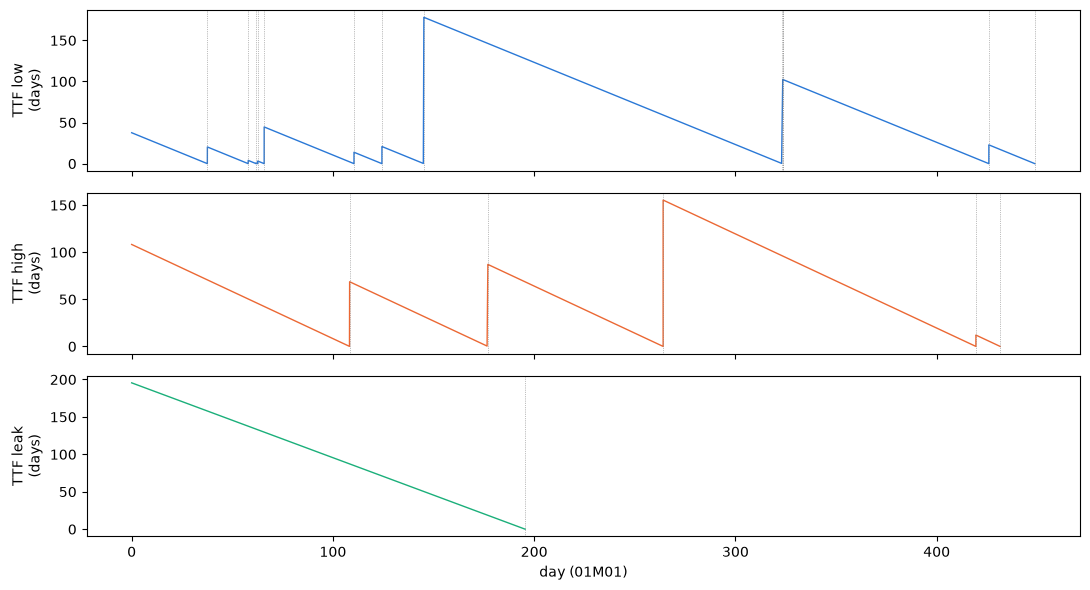

In [52]:
T0_01 = ttf.time.min()
step = ttf.iloc[::200]           # 畫圖用，每 200 筆取一筆
f01 = faults[faults.Tool == "01M01"]

fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, (col, name) in zip(axes, zip(ttf.columns[1:], FAULT_NAMES.values())):
    ax.plot((step.time - T0_01) / 86400, step[col] / 86400, color=FAULT_COLORS[name], lw=1)
    for t in f01[f01.type == name].time:
        ax.axvline((t - T0_01) / 86400, color="gray", lw=0.5, ls=":")
    ax.set_ylabel(f"TTF {name}\n(days)")
axes[-1].set_xlabel("day (01M01)")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "ttf_01M01.png"), dpi=150)
plt.show()

**看到**

- 故障紀錄 1,236 筆，統一名稱、去掉 25 筆完全重複後剩 1,211 筆，共 3 種：壓力過低（low）741、壓力過高（high）333、洩漏（leak）137。
- TTF = 現在距離下一次「這一類」故障還剩多久，每一類一欄，呈鋸齒狀：故障一發生，就跳回到下一次的距離。

**聯想**

官方把它當成 3 個獨立的迴歸，但實際想知道的是「**多久之後會壞、會是哪一種**」。三種故障是互相競爭的：先發生哪一種，機台就停了。機台最後一段還沒出事的時間，不知道下一次什麼時候會壞，等於被 censored。
→ 可視為 **competing risks 的 survival 問題**

## 2. 資料是怎麼被記錄的

先看 01M01 相鄰兩筆的時間間隔。

In [53]:
d = df.drop_duplicates("time")
dt = d.time.diff()
same_run = d.runnum == d.runnum.shift()

print("最常見的間隔（秒）：")
print(dt.value_counts().head(5))
print()
print("同一個 run 內的間隔（秒）：", dt[same_run].describe(percentiles=[.5, .99]).round(1).to_dict())
print("跨 run 的間隔（分鐘）：  ", (dt[~same_run] / 60).describe(percentiles=[.25, .5, .75, .9]).round(1).to_dict())

最常見的間隔（秒）：
time
4.0      3041576
2.0        35779
6.0        29669
116.0       2624
112.0       2020
Name: count, dtype: int64

同一個 run 內的間隔（秒）： {'count': 3115655.0, 'mean': 4.3, 'std': 17.9, 'min': 2.0, '50%': 4.0, '99%': 6.0, 'max': 14236.0}
跨 run 的間隔（分鐘）：   {'count': 3775.0, 'mean': 115.9, 'std': 355.2, 'min': 0.1, '25%': 22.6, '50%': 50.5, '75%': 125.1, '90%': 253.2, 'max': 13241.3}


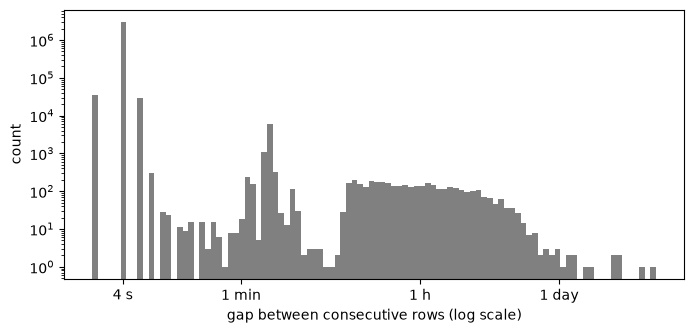

In [54]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log10(dt[dt > 0]), bins=100, color="gray")
ax.set_xticks(np.log10([4, 60, 3600, 86400]), ["4 s", "1 min", "1 h", "1 day"])
ax.set_yscale("log")
ax.set_xlabel("gap between consecutive rows (log scale)")
ax.set_ylabel("count")
fig.savefig(os.path.join(OUT_DIR, "row_gaps.png"), dpi=150)
plt.show()

### 全部 20 台

只讀需要的欄位（`time`、`runnum`）。

In [55]:
times, runs = {}, {}            # 每台機台：去重後排序好的時間、對應的 runnum
for tool in tools:
    s = pd.read_parquet(os.path.join(SENSOR_DIR, f"{tool}.parquet"), columns=["time", "runnum"])
    s = s.drop_duplicates("time").sort_values("time")
    times[tool] = s.time.to_numpy()
    runs[tool] = s.runnum.to_numpy()

T0 = min(t[0] for t in times.values())
print(len(tools), "台機台，共", sum(len(t) for t in times.values()), "個時間點")

20 台機台，共 82071907 個時間點


In [56]:
# 每台機台：觀測多久、有多少比例的時間在加工（相鄰兩筆 <= 60 秒視為加工中）
cov = []
for tool in tools:
    t = times[tool]
    gap = np.diff(t)
    span = t[-1] - t[0]
    cov.append({"tool": tool, "days": span / 86400, "processing_%": 100 * gap[gap <= 60].sum() / span})
cov = pd.DataFrame(cov).set_index("tool")
cov.describe().round(1).loc[["min", "50%", "max"]]

,days,processing_%
min,338.1,18.8
50%,449.5,45.7
max,489.4,55.8


In [57]:
# run 的長度
run_stats = []
for tool in tools:
    r = pd.DataFrame({"time": times[tool], "runnum": runs[tool]}).groupby("runnum").time.agg(["min", "max", "size"])
    run_stats.append(pd.DataFrame({"minutes": (r["max"] - r["min"]) / 60, "rows": r["size"]}))
run_stats = pd.concat(run_stats)
print("run 數：", len(run_stats))
run_stats.describe(percentiles=[.1, .25, .5, .75, .9]).round(1)

run 數： 68025


,minutes,rows
count,68025.0,68025.0
mean,91.0,1206.5
std,101.3,1429.3
min,1.3,20.0
10%,25.5,342.0
25%,40.0,526.0
50%,69.4,898.0
75%,121.8,1576.0
90%,185.8,2483.0
max,9043.1,135545.0


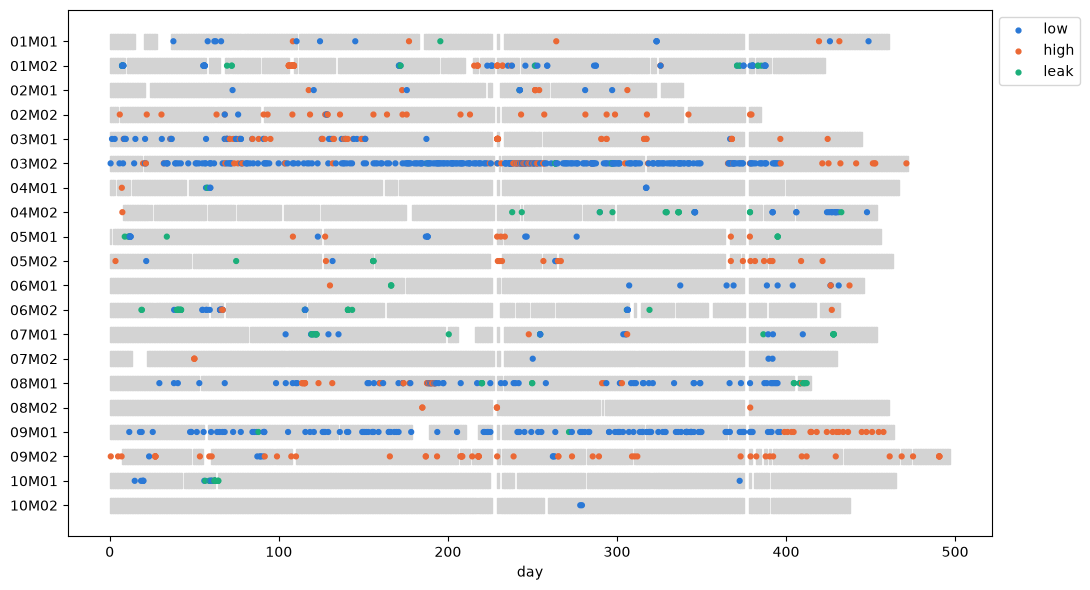

In [58]:
# 每台機台哪幾天有資料（灰）＋故障（點）
fig, ax = plt.subplots(figsize=(11, 6))
for i, tool in enumerate(tools[::-1]):
    days = np.unique((times[tool] - T0) // 86400)
    ax.broken_barh([(x, 1) for x in days], (i - 0.3, 0.6), color="lightgray")
    f = faults[faults.Tool == tool]
    ax.scatter((f.time - T0) / 86400, [i] * len(f), c=f.type.map(FAULT_COLORS), s=12, zorder=3)
ax.set_yticks(range(len(tools)), tools[::-1])
ax.set_xlabel("day")
for name, c in FAULT_COLORS.items():
    ax.scatter([], [], c=c, s=12, label=name)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "fault_timeline.png"), dpi=150)
plt.show()

### 一個 run 內 sensor 長怎樣

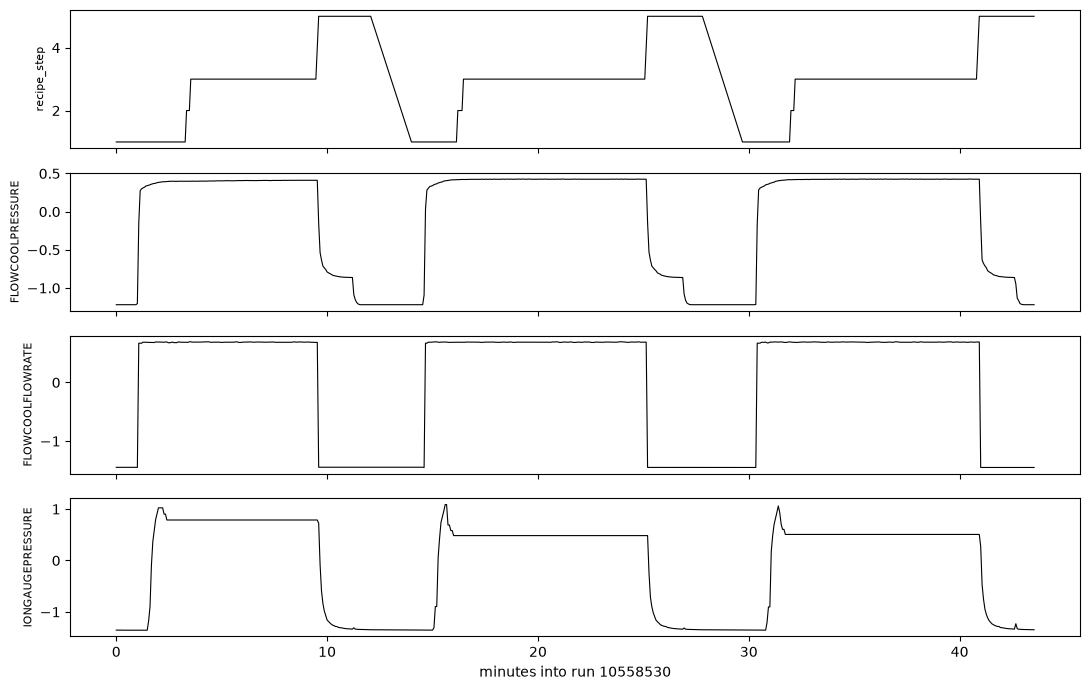

In [59]:
# 挑一個長度接近中位數的 run
r = df.groupby("runnum").size()
run_id = (r - r.median()).abs().idxmin()
one = df[df.runnum == run_id]
minutes = (one.time - one.time.iloc[0]) / 60

fig, axes = plt.subplots(4, 1, figsize=(11, 7), sharex=True)
for ax, col in zip(axes, ["recipe_step", "FLOWCOOLPRESSURE", "FLOWCOOLFLOWRATE", "IONGAUGEPRESSURE"]):
    ax.plot(minutes, one[col], lw=0.8, color="black")
    ax.set_ylabel(col, fontsize=8)
axes[-1].set_xlabel(f"minutes into run {run_id}")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "one_run.png"), dpi=150)
plt.show()

**看到**

- 同一個 run 內幾乎都是 4 秒一筆（99% ≤ 6 秒）；run 和 run 之間的間隔中位數 50 分鐘，長的可以到好幾天。
- 20 台機台各觀測 338～489 天，但只有 19%～56%（中位數 46%）的時間在加工 → **只在加工時記錄**。
- 一個 run 的長度中位數 69 分鐘（IQR 40～122），大約 900 筆。
- 時間軸：故障在機台之間很不平均（03M02 一台就有 356 筆），而且常常一群一群出現。大約第 228 天和第 376 天，所有機台同時沒有資料。
- 一個 run 內，sensor 跟著 recipe step 在幾個固定水準之間切換，大約 15 分鐘重複一次 → 4 秒的值主要反映「現在在哪個步驟」，不是設備的狀態。

**決定**

- 取樣不規則（4 秒 vs 好幾小時的空白）→ 不直接用 4 秒序列，**聚合成固定的時間窗**，並把「與上一個窗的間隔」當成特徵。
- 窗內用 mean／std／min／max 摘要，把步驟切換造成的跳動平均掉。

## 3. 故障紀錄 → 定義 event

In [60]:
pd.crosstab(faults.Tool, faults.type, margins=True)

type,high,leak,low,All
Tool,,,,
01M01,5,1,13,19
01M02,40,16,53,109
02M01,7,1,9,17
02M02,27,0,5,32
03M01,51,0,40,91
03M02,49,9,298,356
04M01,1,1,7,9
04M02,1,15,21,37
05M01,7,7,14,28


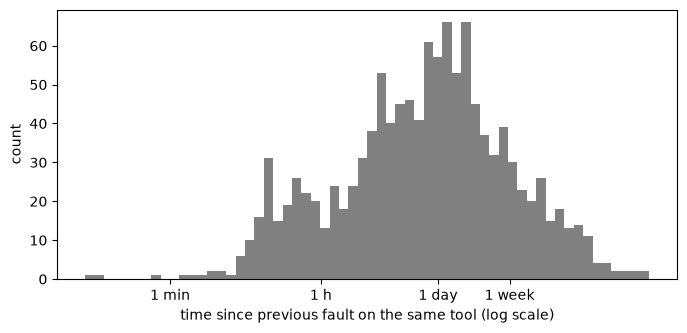

距前一筆故障 < 1 分鐘：0%
距前一筆故障 < 10 分鐘：2%
距前一筆故障 < 1 小時：15%


In [61]:
# 同一台機台，相鄰兩筆故障隔多久
faults["prev_time"] = faults.groupby("Tool").time.shift()
gap_min = (faults.time - faults.prev_time) / 60

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log10(gap_min.dropna().clip(lower=0.1)), bins=60, color="gray")
ax.set_xticks(np.log10([1, 60, 1440, 10080]), ["1 min", "1 h", "1 day", "1 week"])
ax.set_xlabel("time since previous fault on the same tool (log scale)")
ax.set_ylabel("count")
fig.savefig(os.path.join(OUT_DIR, "interfault_gaps.png"), dpi=150)
plt.show()

for m, label in [(1, "1 分鐘"), (10, "10 分鐘"), (60, "1 小時")]:
    print(f"距前一筆故障 < {label}：{100 * (gap_min < m).mean():.0f}%")

In [62]:
# 兩筆故障之間，機台有沒有恢復生產（中間有沒有 sensor 資料）
def rows_between(tool, t_from, t_to):
    t = times[tool]
    return np.searchsorted(t, t_to) - np.searchsorted(t, t_from, side="right")

faults["rows_since_prev"] = [
    rows_between(r.Tool, r.prev_time, r.time) if pd.notna(r.prev_time) else np.nan
    for r in faults.itertuples()
]
has_prev = faults.prev_time.notna()
no_prod = faults.rows_since_prev == 0
print(f"跟前一筆故障之間沒有任何 sensor 資料：{100 * no_prod[has_prev].mean():.0f}%")

pd.crosstab(pd.cut(gap_min[has_prev], [0, 10, 60, 1440, np.inf], labels=["<10 min", "10-60 min", "1 h-1 day", ">1 day"]),
            no_prod[has_prev].map({True: "沒恢復生產", False: "有恢復生產"}))

跟前一筆故障之間沒有任何 sensor 資料：14%


rows_since_prev,有恢復生產,沒恢復生產
row_0,,
<10 min,16,11
10-60 min,65,84
1 h-1 day,409,57
>1 day,539,10


**看到**

- 相鄰兩筆故障的間隔分布很廣：15% 在 1 小時內，最常見的是 1 天左右。
- 14% 的故障跟前一筆之間**完全沒有 sensor 資料** = 機台還沒恢復生產就又報錯。間隔越短越常這樣（10～60 分鐘的有一半以上沒恢復生產）。

**決定**

- 沒恢復生產就再次報錯 → 視為**同一次事故（incident）**。否則同一次停機會被算成好幾個 event。
- 用「有沒有恢復生產」來合併，而不是固定時間（例如 1 小時）：有些 10 分鐘內的報錯中間其實有生產（16 筆），用固定時間會誤併。

In [63]:
# 沒恢復生產就併進上一個事故
faults["new_incident"] = ~no_prod
faults["incident_no"] = faults.groupby("Tool").new_incident.cumsum()

incidents = faults.groupby(["Tool", "incident_no"]).agg(
    start=("time", "first"), end=("time", "last"),
    type=("type", "first"),                  # event = 第一筆故障的類型
    n_alarms=("time", "size"), n_types=("type", "nunique"),
).reset_index()

print(len(faults), "筆故障 ->", len(incidents), "次事故")
print("一次事故包含多種故障類型：", (incidents.n_types > 1).sum(), "次")
incidents.type.value_counts()

1211 筆故障 -> 1049 次事故
一次事故包含多種故障類型： 36 次


type
low     703
high    241
leak    105
Name: count, dtype: int64

1,211 筆故障 → 1,049 次事故，只有 36 次混了多種類型 → **event = 事故第一筆故障的類型**。

## 4. 重複發生的事故 → 怎麼變成 survival 樣本（設計 episode）

**問題**：survival 的每個樣本要有起點（time zero）、event、censoring。
但第 3 節看到同一台機台會一再出事，一台機台不能只當一個樣本。

**選擇**：每次事故後、機台恢復生產時，時間歸零重新算
（recurrent event 裡的 gap time 做法）。
→ 把這樣切出來的一段叫做 **episode**：從恢復生產開始，到下一次事故為止；
機台最後一段還沒出事的 = 截尾 censored。

**為什麼這樣選**
- 想回答的是「距離下一次事故還多久」，起點就該是上一次事故結束
- 官方 TTF 也是每次故障後歸零（第 1 節的鋸齒狀），定義一致
- 停機、維修的時間不算進去（那段時間機台不在 risk set 裡）


In [64]:
episodes = []
for tool in tools:
    t = times[tool]
    start = t[0]
    for inc in incidents[incidents.Tool == tool].itertuples():
        if inc.start >= t[0]:                 # sensor 紀錄開始前的故障，沒有歷史可以學，略過
            episodes.append({"tool": tool, "start": start, "end": inc.start, "event": inc.type, "n_alarms": inc.n_alarms})
        j = np.searchsorted(t, inc.end, side="right")   # 事故後第一筆資料 = 下一個 episode 開始
        if j == len(t):
            start = None
            break
        start = t[j]
    if start is not None:
        episodes.append({"tool": tool, "start": start, "end": t[-1], "event": "censored", "n_alarms": 0})

ep = pd.DataFrame(episodes)
ep["hours"] = (ep.end - ep.start) / 3600
print(len(ep), "個 episode")
ep.event.value_counts()

1067 個 episode


event
low         703
high        239
leak        105
censored     20
Name: count, dtype: int64

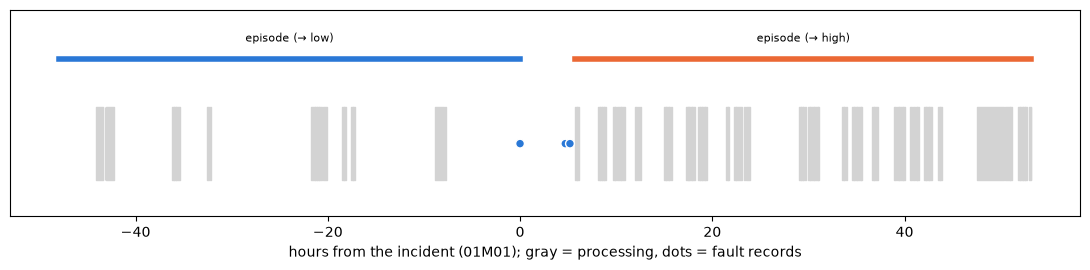

,time,type,rows_since_prev
12,31212736,low,373937.0
13,31229684,low,0.0
14,31231428,low,0.0


In [65]:
# 真實例子：找一個合併了 3 筆以上故障的事故，畫前後 2 天
ex = incidents[incidents.n_alarms >= 3].iloc[0]
tool, lo, hi = ex.Tool, ex.start - 2 * 86400, ex.end + 2 * 86400
t = times[tool]
t = t[(t >= lo) & (t <= hi)]
brk = np.where(np.diff(t) > 60)[0]            # 間隔 > 60 秒就斷開 = 不在加工
seg_start = np.r_[t[0], t[brk + 1]]
seg_end = np.r_[t[brk], t[-1]]

fig, ax = plt.subplots(figsize=(11, 2.8))
h = lambda x: (x - ex.start) / 3600          # 以事故開始為 0，單位小時
ax.broken_barh([(h(a), h(b) - h(a)) for a, b in zip(seg_start, seg_end)], (0.35, 0.3), color="lightgray")
f = faults[(faults.Tool == tool) & faults.time.between(lo, hi)]
ax.scatter(h(f.time), [0.5] * len(f), c=f.type.map(FAULT_COLORS), s=40, zorder=3, edgecolor="white")
e = ep[(ep.tool == tool) & (ep.end >= lo) & (ep.start <= hi)]
for r in e.itertuples():
    a, b = h(max(r.start, lo)), h(min(r.end, hi))
    ax.plot([a, b], [0.85, 0.85], color=FAULT_COLORS.get(r.event, "gray"), lw=4)
    ax.text((a + b) / 2, 0.92, f"episode (→ {r.event})", ha="center", fontsize=8)
ax.set_ylim(0.2, 1.05)
ax.set_yticks([])
ax.set_xlabel(f"hours from the incident ({tool}); gray = processing, dots = fault records")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "incident_example.png"), dpi=150)
plt.show()
f[["time", "type", "rows_since_prev"]]

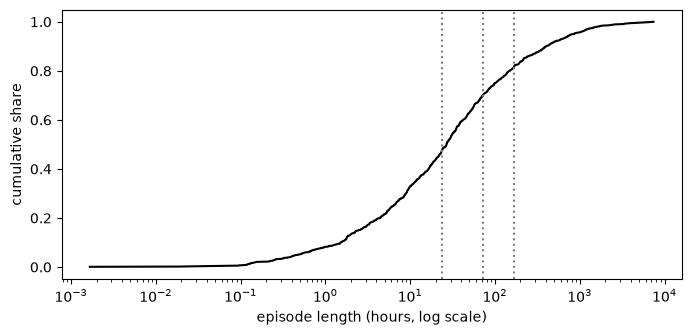

有事故的 episode 在  24 小時內結束：48%
有事故的 episode 在  72 小時內結束：70%
有事故的 episode 在 168 小時內結束：82%
有事故的 episode 在 336 小時內結束：88%


In [66]:
# episode 有多長？有事故的 episode 在多久內結束？
ev = ep[ep.event != "censored"]
x = np.sort(ev.hours)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(x, np.arange(1, len(x) + 1) / len(x), color="black")
for hh in [24, 72, 168]:
    ax.axvline(hh, color="gray", ls=":")
ax.set_xscale("log")
ax.set_xlabel("episode length (hours, log scale)")
ax.set_ylabel("cumulative share")
fig.savefig(os.path.join(OUT_DIR, "episode_length_ecdf.png"), dpi=150)
plt.show()

for hh in [24, 72, 168, 336]:
    print(f"有事故的 episode 在 {hh:>3} 小時內結束：{100 * (ev.hours <= hh).mean():.0f}%")

In [67]:
# 每台機台有幾個 episode
ep.groupby("tool").size().describe().round(1)

count     20.0
mean      53.4
std       74.1
min        3.0
25%       14.8
50%       25.5
75%       58.8
max      323.0
dtype: float64

In [68]:
# 定義確定了，存起來給 02 用
ep["episode_id"] = ep.tool + "_" + ep.groupby("tool").cumcount().astype(str).str.zfill(3)
ep[["episode_id", "tool", "start", "end", "event", "n_alarms", "hours"]].to_parquet(
    os.path.join(PROCESSED_DIR, "episodes.parquet"), index=False)

**看到**

- 照這個定義得到 1,067 個 episode：壓力過低 703、壓力過高 239、洩漏 105、截尾 20（每台機台的最後一段）。壓力過高比事故數少 2 個，因為那 2 次發生在 sensor 紀錄開始之前，沒有歷史可以學。
- 例子：01M01 一次壓力過低之後，幾小時內又報了 2 次，中間沒有生產（`rows_since_prev = 0`）→ 合併成一次事故；機台恢復生產後才開始下一個 episode。
- episode 長度差很多：中位數 27 小時，IQR 7～111 小時。有事故的 episode 中，48% 在 1 天內結束、**82% 在 7 天內**，拉長到 14 天也只到 88%。
- 每台機台有 3～323 個 episode（中位數 26）→ 同一台機台會一再出事。

**決定**

- **預測範圍 = 7 天**：涵蓋 82% 的事故，再拉長的收益很小；7 天內沒出事就視為截尾 censored。

## 5. Table 1：依 event 類型比較 episode


In [69]:
ep = ep.sort_values(["tool", "start"]).reset_index(drop=True)
ep["prev_type"] = ep.groupby("tool").event.shift().fillna("none")

# 過去 30 天，同一台機台出過幾次事故（episode 開始時已知）
inc_end = ep[ep.event != "censored"].groupby("tool").end.apply(np.sort)
ep["inc_30d"] = [
    np.sum((inc_end[r.tool] <= r.start) & (inc_end[r.tool] > r.start - 30 * 86400)) for r in ep.itertuples()
]

# 故障時是不是正在加工（故障前最後一筆資料在 60 秒內）
def last_row_gap(tool, t_fault):
    t = times[tool]
    i = np.searchsorted(t, t_fault) - 1
    return t_fault - t[i] if i >= 0 else np.nan

ep["during_processing"] = [
    last_row_gap(r.tool, r.end) <= 60 if r.event != "censored" else np.nan for r in ep.itertuples()
]

In [70]:
from tableone import TableOne

yes_no = lambda m: m.map({True: "yes", False: "no"})
t1_data = ep.assign(
    multi_alarm=yes_no(ep.n_alarms.gt(1).where(ep.event != "censored")),       # 截尾沒有事故 -> 缺值
    during_processing=yes_no(ep.during_processing),
)
t1 = TableOne(
    t1_data,
    columns=["hours", "inc_30d", "prev_type", "multi_alarm", "during_processing"],
    categorical=["prev_type", "multi_alarm", "during_processing"],
    nonnormal=["hours", "inc_30d"],
    groupby="event",
    order={"event": ["low", "high", "leak", "censored"], "prev_type": ["none", "low", "high", "leak"],
           "multi_alarm": ["yes", "no"], "during_processing": ["yes", "no"]},
    rename={"hours": "episode length, h", "inc_30d": "incidents in prior 30 d",
            "prev_type": "previous incident", "multi_alarm": "incident with >1 alarm",
            "during_processing": "fault during processing"},
    missing=False, include_null=False, pval=False, decimals=1,
).tableone

# 加上每組的機台數；截尾沒有事故，那兩列留白
n_tools = t1_data.groupby("event").tool.nunique().reindex(t1.columns.get_level_values(1)).fillna(ep.tool.nunique())
t1 = pd.concat([t1.iloc[:1], pd.DataFrame([n_tools.astype(int).to_numpy()], index=pd.MultiIndex.from_tuples([("n tools", "")]), columns=t1.columns), t1.iloc[1:]])
t1 = t1.replace("0 (nan)", "")
t1.to_csv(os.path.join(OUT_DIR, "table1.csv"))
t1


Grouped by event                                                                         
                                                       Overall              low              high            leak              censored
n                                                         1067              703               239             105                    20
n tools                                                     20               19                17              13                    20
episode length, h, median [Q1,Q3]             27.4 [6.7,111.2]  24.0 [7.4,68.2]  74.5 [9.3,257.9]  5.8 [0.9,47.5]  534.7 [141.4,1101.4]
incidents in prior 30 d, median [Q1,Q3]        10.0 [4.0,20.0]  13.0 [6.0,25.0]    5.0 [2.0,11.0]  7.0 [3.0,11.0]         3.0 [2.0,5.5]
previous incident, n (%)                none          20 (1.9)         11 (1.6)           6 (2.5)         3 (2.9)               0 (0.0)
                                        low         703 (65.9)       584 (83.1)         72 (30.1)       40 (38.1)              7 (35.0)
                                        high        239 (22.4)        72 (10.2)        153 (64.0)         4 (3.8)             10 (50.0)
                                        leak         105 (9.8)         36 (5.1)           8 (3.3)       58 (55.2)              3 (15.0)
incident with >1 alarm, n (%)           yes           70 (6.7)         41 (5.8)          23 (9.6)         6 (5.7)                      
                                        no          977 (93.3)       662 (94.2)        216 (90.4)       99 (94.3)                      
fault during processing, n (%)          yes         411 (39.3)       253 (36.0)         86 (36.0)       72 (68.6)                      
                                        no          636 (60.7)       450 (64.0)        153 (64.0)       33 (31.4)

In [71]:
# 前一次事故類型 -> 這一次（列 %）
pd.crosstab(ep.prev_type, ep.event, normalize="index").mul(100).round(0)[["low", "high", "leak", "censored"]]

event,low,high,leak,censored
prev_type,,,,
high,30.0,64.0,2.0,4.0
leak,34.0,8.0,55.0,3.0
low,83.0,10.0,6.0,1.0
none,55.0,30.0,15.0,0.0


**看到**

- **前一次事故的類型跟這一次高度相關**：壓力過低之後 83% 還是壓力過低，壓力過高之後 64% 還是過高，洩漏之後 55% 還是洩漏。
- 壓力過低的 episode，過去 30 天的事故比較多（中位數 13 次，壓力過高是 5 次）。這也跟機台有關：壓力過低集中在少數機台（03M02、09M01）。
- 洩漏的 episode 很短（中位數 5.8 小時），而且 69% 發生在加工中；壓力過低、過高都只有 36% 發生在加工中 → 很多故障前一刻根本沒有 sensor 資料。
- 截尾的 20 個 episode 很長（中位數 535 小時）：機台的最後一段通常是長時間沒出事。

**決定**

- 事故歷史當成輸入
- 只有約 4 成的故障前一刻有 sensor 資料 → 不能只看「當下」，要看一段歷史。

## 6. 故障前 24 小時，sensor 有沒有可見的趨勢或偏移？

- 對齊每次事故的時間（0 = 故障），只用同一個 episode 內的資料
- 每 30 分鐘一格取**平均**（sensor 會隨 recipe step 在兩個水準間切換，中位數會亂跳；平均 ≈ 這段時間處在高水準的比例）
- **每台機台一條細線**，再減去該機台自己在 −24～−12 小時的平均，讓不同機台可以放在一起比
- 彩色粗線 = 全部機台的中位數

In [72]:
SENSORS = ["FLOWCOOLPRESSURE", "FLOWCOOLFLOWRATE", "IONGAUGEPRESSURE"]
BIN_H = 0.5

per_tool = []        # 每台機台 x 故障類型 x 30 分鐘格 的平均
n_ep = []            # 每一格有幾個 episode 有資料
for tool in tools:
    s = pd.read_parquet(os.path.join(SENSOR_DIR, f"{tool}.parquet"), columns=["time"] + SENSORS).drop_duplicates()
    rows = []
    for r in ep[(ep.tool == tool) & (ep.event != "censored")].itertuples():
        w = s[(s.time >= max(r.start, r.end - 24 * 3600)) & (s.time < r.end)].copy()
        w["h"] = np.floor((w.time - r.end) / 3600 / BIN_H) * BIN_H     # -24 ... -0.5
        w["type"], w["episode"] = r.event, r.Index
        rows.append(w)
    if not rows:
        continue
    w = pd.concat(rows)
    n_ep.append(w.groupby(["type", "h"]).episode.nunique())
    m = w.groupby(["type", "h"])[SENSORS].mean()
    ref = w[w.h < -12].groupby("type")[SENSORS].mean()
    per_tool.append((m - ref).assign(tool=tool).reset_index())

per_tool = pd.concat(per_tool)
n_ep = pd.concat(n_ep).groupby(level=[0, 1]).sum()

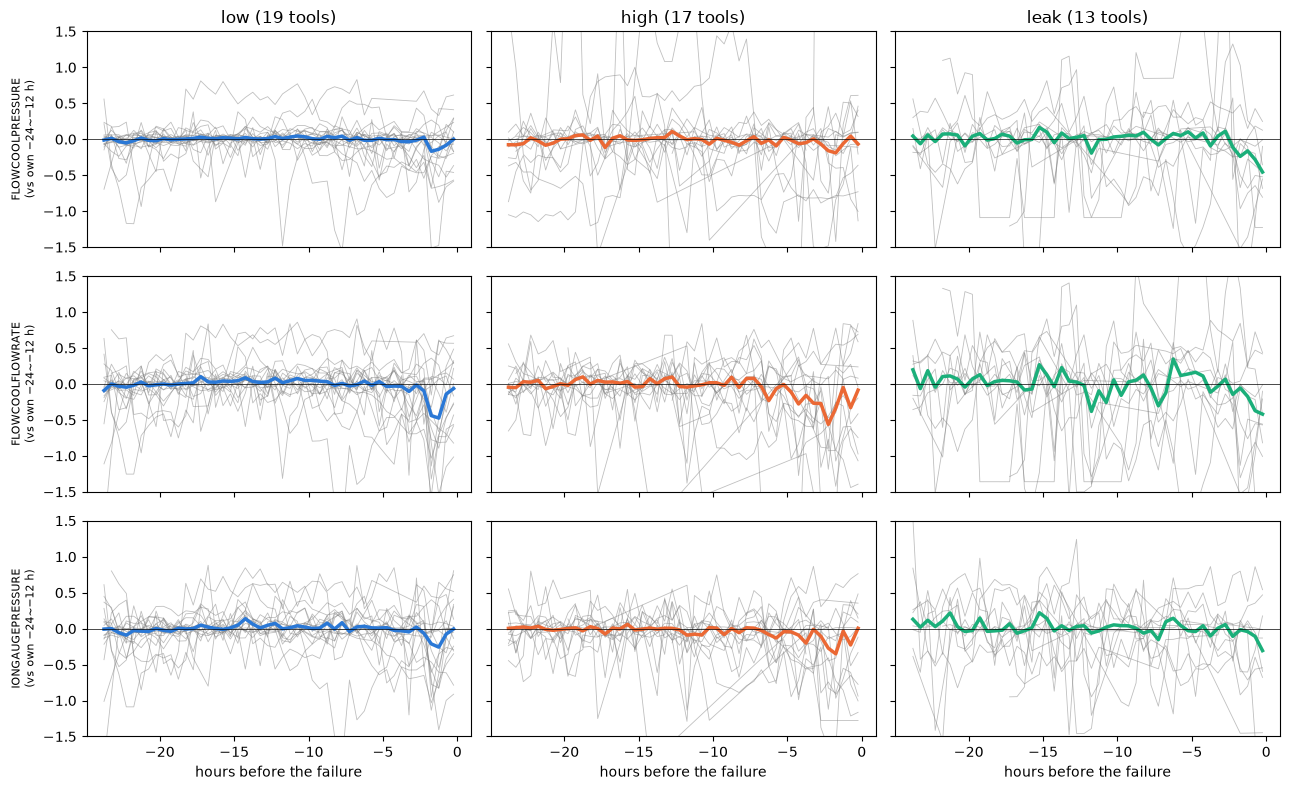

In [73]:
types = ["low", "high", "leak"]
fig, axes = plt.subplots(len(SENSORS), 3, figsize=(13, 8), sharex=True, sharey="row")
for j, ftype in enumerate(types):
    d = per_tool[per_tool.type == ftype]
    for i, col in enumerate(SENSORS):
        ax = axes[i, j]
        for tool, g in d.groupby("tool"):
            ax.plot(g.h + BIN_H / 2, g[col], color="gray", lw=0.6, alpha=0.5)
        overall = d.groupby("h")[col].median()
        ax.plot(overall.index + BIN_H / 2, overall, color=FAULT_COLORS[ftype], lw=2.5)
        ax.axhline(0, color="black", lw=0.5)
        if i == 0:
            ax.set_title(f"{ftype} ({d.tool.nunique()} tools)")
        if j == 0:
            ax.set_ylabel(f"{col}\n(vs own −24~−12 h)", fontsize=8)
        ax.set_ylim(-1.5, 1.5)
for ax in axes[-1]:
    ax.set_xlabel("hours before the failure")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "prefailure_trends.png"), dpi=150)
plt.show()

In [74]:
# 每個時段有幾個 episode 有資料（越接近故障越少）
n_ep.unstack("type")[types].loc[[-24.0, -12.0, -6.0, -1.0, -0.5]]

type,low,high,leak
h,,,
-24.0,242,70,15
-12.0,304,62,22
-6.0,349,82,35
-1.0,456,100,73
-0.5,430,107,90


**看到**

- 故障前 24～3 小時，三種故障的整體趨勢（粗線）都貼在 0 附近 → **沒有看到逐漸的漂移**。
- 最後 2～3 小時才開始下降：壓力過低的 Flowcool 流量和離子真空計壓力，在最後 1～2 小時下降約 0.4；壓力過高的 Flowcool 流量大約從 −6 小時開始往下；洩漏的 Flowcool 壓力在最後 2 小時下降，但機台之間（細線）的差異比這個變化大得多。
- 越早的時段，有資料的 episode 越少（例如 −24 小時只有 242 個壓力過低的 episode），因為很多 episode 本來就不到 24 小時。

**決定**

- sensor 可能有**短期**（幾小時內）的訊號，但沒有長期漂移 → 輸入要包含最近幾小時的 sensor 歷史。歷史長度在 training 比較 **L = 12（約 1 小時）和 L = 64（約 7 小時）**。
- 預期大部分的可預測性還是來自事故歷史（第 5 節），sensor 的貢獻可能有限。

## 7. 這是 longitudinal data

In [75]:
# 01M01 的 FLOWCOOLPRESSURE，隔多久還相關？
x = df.drop_duplicates("time").FLOWCOOLPRESSURE.reset_index(drop=True)
for lag, label in [(1, "4 秒"), (15, "1 分鐘"), (75, "5 分鐘"), (225, "15 分鐘"), (900, "1 小時")]:
    print(f"隔 {label:<6}的自相關：{x.autocorr(lag):.2f}")

隔 4 秒   的自相關：1.00
隔 1 分鐘  的自相關：0.92
隔 5 分鐘  的自相關：0.73
隔 15 分鐘 的自相關：0.78
隔 1 小時  的自相關：0.72


把前面的線索放在一起：

| 線索 | 出處 |
|---|---|
| 同一台機台被重複觀測一年以上 | 第 2 節 |
| 事件會一再發生（每台 3～323 個 episode） | 第 4 節 |
| 前一次事故會影響下一次 | 第 5 節 |
| sensor 和事故歷史都隨時間改變 | 第 2、6 節 |
| 相鄰時間點高度相關（Flowcool 壓力隔 1 小時，自相關仍有 0.72） | 上面 |

→ 這是 **longitudinal data**：同一個單位（機台）隨時間重複測量，事件也會重複發生。這會影響兩件事：

1. **樣本怎麼建**：想在 ‘任何時間點 t’ 預測未來 → 每個時間點都是一個樣本（landmark）。輸入 = t 以前的歷史，標籤 = 從 t 到下一次事故的時間與類型。
2. **怎麼切分才不會洩漏**：相鄰的兩個預測時間點 t 和 t + 5 分鐘，輸入歷史幾乎完全重疊（64 個窗中有 63 個一樣），而且指向同一次故障→ 用**時間切分**（data_prep）。

## 8. 輸入要設計成什麼樣子

假設把每個 episode 切成 5 分鐘的窗，看看會長怎樣。

In [76]:
WINDOW_S = 300

win = []
for tool in tools:
    t = times[tool]
    e = ep[ep.tool == tool]
    ep_idx = np.searchsorted(e.start.to_numpy(), t, side="right") - 1      # 每筆資料屬於哪個 episode
    ok = (ep_idx >= 0) & (t < e.end.to_numpy()[ep_idx.clip(0)])             # 故障當下及之後的資料不算
    w = pd.DataFrame({"episode": e.index.to_numpy()[ep_idx[ok]], "win": t[ok] // WINDOW_S, "time": t[ok]})
    win.append(w.groupby(["episode", "win"]).time.agg(["size", "max"]).reset_index())
win = pd.concat(win).rename(columns={"size": "rows", "max": "t_last"})
win["gap_min"] = win.groupby("episode").t_last.diff() / 60

print(len(win), "個窗")
print("每窗筆數（滿的 = 75）：", win.rows.quantile([.1, .25, .5, .75]).to_dict())
print("相鄰兩窗間隔（分鐘）：  ", win.gap_min.quantile([.5, .75, .9, .95, .99]).round(1).to_dict())

1295231 個窗
每窗筆數（滿的 = 75）： {0.1: 36.0, 0.25: 53.0, 0.5: 75.0, 0.75: 75.0}
相鄰兩窗間隔（分鐘）：   {0.5: 5.0, 0.75: 5.0, 0.9: 6.5, 0.95: 13.5, 0.99: 116.4}


In [77]:
# 每個 episode 有幾個窗；看過去 L 個窗，實際涵蓋多少小時
n_win = win.groupby("episode").size()
print("每個 episode 的窗數：", n_win.quantile([.1, .25, .5, .75, .9]).to_dict())
for L in [12, 64]:
    span_h = (win.t_last - win.groupby("episode").t_last.shift(L - 1)) / 3600
    print(f"L = {L:>2}：{100 * (n_win >= L).mean():.0f}% 的 episode 填得滿，"
          f"實際涵蓋時間中位數 {span_h.median():.1f} h（IQR {span_h.quantile(.25):.1f}–{span_h.quantile(.75):.1f}）")

每個 episode 的窗數： {0.1: 11.0, 0.25: 42.0, 0.5: 156.0, 0.75: 651.0, 0.9: 2551.2}
L = 12：90% 的 episode 填得滿，實際涵蓋時間中位數 1.0 h（IQR 0.9–1.5）
L = 64：68% 的 episode 填得滿，實際涵蓋時間中位數 7.4 h（IQR 6.1–10.4）


In [78]:
# 5 分鐘窗的平均值，隔幾個窗還相關？（01M01）
w01 = df.drop_duplicates("time").assign(win=lambda d: d.time // WINDOW_S).groupby("win")[SENSORS].mean()
for lag in [1, 3, 12, 64]:
    print(f"隔 {lag:>2} 個窗：", {c: round(w01[c].autocorr(lag), 2) for c in SENSORS})

隔  1 個窗： {'FLOWCOOLPRESSURE': np.float64(0.8), 'FLOWCOOLFLOWRATE': np.float64(0.29), 'IONGAUGEPRESSURE': np.float64(0.3)}
隔  3 個窗： {'FLOWCOOLPRESSURE': np.float64(0.85), 'FLOWCOOLFLOWRATE': np.float64(0.53), 'IONGAUGEPRESSURE': np.float64(0.53)}
隔 12 個窗： {'FLOWCOOLPRESSURE': np.float64(0.74), 'FLOWCOOLFLOWRATE': np.float64(0.27), 'IONGAUGEPRESSURE': np.float64(0.25)}
隔 64 個窗： {'FLOWCOOLPRESSURE': np.float64(0.58), 'FLOWCOOLFLOWRATE': np.float64(0.12), 'IONGAUGEPRESSURE': np.float64(0.11)}


**看到**

- 5 分鐘窗：一個 run（中位數 69 分鐘）大約切成 14 個窗；一半以上的窗是滿的（75 筆 = 5 分鐘 ÷ 4 秒）。聚合後，90% 的相鄰窗間隔 ≤ 6.5 分鐘 → 不規則的 4 秒資料變成**近乎等距**的序列。
- 窗與窗之間的自相關：隔 3 個窗（15 分鐘）比隔 1 個窗還高，呼應第 2 節的約 15 分鐘製程循環。Flowcool 壓力隔 64 個窗仍有 0.58；其他 sensor 隔 12 個窗之後就降到 0.3 以下。
- 歷史長度：L = 12 約 1 小時，90% 的 episode 填得滿；L = 64 約 7.4 小時，68% 填得滿。

**決定**

- 時間窗 = 5 分鐘，每個窗算 mean／std／min／max，加上與上一個窗的間隔。
- 先把每筆資料指派到所屬的 episode 再聚合，故障當下和之後的資料不算 → 一個窗不會跨過故障。
- 歷史長度主要用 L = 64（大約一個班次），另外比較 L = 12 和 L = 1（只看當下）。

## 結論

| # | 發現 | 決定 | 在哪裡做 |
|---|---|---|---|
| 1 | 每 4 秒一筆，但只在加工時記錄（19%～56% 的時間） | 聚合成 5 分鐘窗 + 間隔特徵 | data_prep |
| 2 | sensor 隨 recipe step 切換，約 15 分鐘一個循環 | 窗內取 mean／std／min／max | data_prep |
| 3 | 3 種故障互相競爭，而且有截尾 | competing risks survival：預測「多久後、哪一種」 | training |
| 4 | 14% 的故障之間機台沒有恢復生產 | 合併成同一次事故；event = 第一筆的類型 | data_prep |
| 5 | 82% 有事故的 episode 在 7 天內結束 | 預測範圍 7 天，超過就截尾 | data_prep |
| 6 | 前一次事故的類型強烈預測下一次 | 事故歷史當成輸入 | data_prep |
| 7 | 只有約 4 成故障前一刻有資料；故障前 2～3 小時才有小幅變化，沒有長期漂移 | 用 sensor 歷史；比較 L = 1／12／64 | training |
| 8 | 同一台機台重複觀測、事件重複發生、相鄰時間點高度相關 | longitudinal：每個時間點都是一個樣本；用時間切分防止洩漏 | data_prep |